# EDA bộ dữ liệu SPAFS: Platts, Brent và các luồng mô hình

**Mục tiêu:** giúp nhóm hiểu dữ liệu thực sự được dùng trong pipeline — phạm vi mẫu, từng cột, chất lượng, phân phối, biến động theo thời gian, mối liên hệ giữa thị trường và tình trạng sẵn sàng của dữ liệu tin tức.

Notebook lấy **`spafs_full_features_daily.parquet`** làm bảng phân tích chính; đối chiếu với canonical panel, Stream 1 (RQ1) và Stream 2 (RQ2). Các con số được tính lại từ file mỗi lần chạy, không ghi cứng kết quả phân tích.

> **Cách đọc:** chạy tuần tự từ đầu đến cuối. Đây là EDA mô tả, không phải kiểm định nhân quả hay đánh giá năng lực dự báo. Không tự động loại outlier hoặc điền giá trị thiếu.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (12, 5), "font.size": 10, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 80)
pd.set_option("display.max_rows", 80)

DATASETS = {
    "Canonical panel": Path("data/interim/canonical_market_panel.parquet"),
    "Brent native": Path("data/interim/brent_continuous.parquet"),
    "Features daily": Path("data/processed/spafs_full_features_daily.parquet"),
    "Stream 1 (RQ1)": Path("data/processed/stream1_econometric_2008_2025.parquet"),
    "Stream 2 (RQ2)": Path("data/processed/stream2_aligned_nlp_2017_2025.parquet"),
    "Weekly robustness": Path("data/processed/weekly_price_robustness.parquet"),
}
AUDITS = {
    "canonical": Path("reports/data_quality/canonical_panel_audit.json"),
    "partition": Path("reports/data_quality/partition_audit.json"),
    "pipeline": Path("reports/data_quality/pipeline_manifest.json"),
}
repo_root = next((p for p in (Path.cwd(), *Path.cwd().parents)
                  if (p / DATASETS["Features daily"]).is_file()), None)
if repo_root is None:
    raise FileNotFoundError(
        f"Không tìm thấy {DATASETS['Features daily']}. Hãy chạy notebook từ thư mục dự án hoặc thư mục con."
    )

loaded = {}
for label, relative_path in DATASETS.items():
    path = repo_root / relative_path
    if not path.is_file():
        if label == "Weekly robustness":
            continue
        raise FileNotFoundError(f"Thiếu dataset bắt buộc: {path}")
    loaded[label] = pd.read_parquet(path)

for label in ("Features daily", "Stream 1 (RQ1)", "Stream 2 (RQ2)"):
    frame = loaded[label]
    if "market_date" not in frame.columns:
        raise ValueError(f"{label} thiếu cột market_date")
    frame["market_date"] = pd.to_datetime(frame["market_date"], errors="raise")
    frame.sort_values("market_date", inplace=True)
    frame.reset_index(drop=True, inplace=True)

df = loaded["Features daily"].copy()
brent_native = loaded["Brent native"].copy()
brent_native["market_date"] = pd.to_datetime(brent_native["market_date"], errors="raise")
if "brent_return_pct" not in brent_native:
    raise ValueError("Brent native dataset thiếu brent_return_pct")
if brent_native["market_date"].duplicated().any():
    raise ValueError("Brent native dataset có market_date trùng lặp")
# Preserve Brent's own trading calendar; do not infer a zero return on ICE holidays.
brent_returns = brent_native.set_index("market_date")["brent_return_pct"]
df["brent_native_return_pct"] = df["market_date"].map(brent_returns)
required = {"market_date", "MG95", "MG92", "DO_001", "DO_005", "brent_close",
            "mg95_return_pct", "brent_return_pct_aligned", "target_return_pct",
            "target_direction", "target_direction_tri"}
missing_required = required.difference(df.columns)
if missing_required:
    raise ValueError(f"Features daily thiếu cột bắt buộc: {sorted(missing_required)}")

for audit_name, relative_path in AUDITS.items():
    path = repo_root / relative_path
    if path.is_file():
        with path.open(encoding="utf-8") as file:
            loaded[f"audit:{audit_name}"] = json.load(file)

print(f"Thư mục dữ liệu: {repo_root}")
print(f"Bảng EDA chính: {DATASETS['Features daily']}")
print(f"Đã nạp {len(loaded)} bảng/báo cáo; không xóa hàng hoặc tự điền missing values.")

Thư mục dữ liệu: C:\Users\Win10\petro95_workflow_team
Bảng EDA chính: data\processed\spafs_full_features_daily.parquet
Đã nạp 9 bảng/báo cáo; không xóa hàng hoặc tự điền missing values.


## 1. Bản đồ dữ liệu và phạm vi mẫu

Pipeline có nhiều tầng: **interim** giữ dữ liệu đã chuẩn hóa/ghép; **processed** chứa đặc trưng mô hình và hai luồng mẫu. Stream 1 và Stream 2 là các mẫu theo mục tiêu nghiên cứu, không phải hai bộ quan sát độc lập hoàn toàn.

Bảng đầu tiên cho biết kích thước và phạm vi ngày thực tế của từng dataset có trong repo. Hãy xác nhận đúng phiên bản dữ liệu trước khi diễn giải kết quả.

In [2]:
inventory_rows = []
for label, frame in loaded.items():
    if not isinstance(frame, pd.DataFrame):
        continue
    date_col = "market_date" if "market_date" in frame.columns else ("week_period" if "week_period" in frame.columns else None)
    if date_col:
        dates = frame[date_col].dt.to_timestamp() if isinstance(frame[date_col].dtype, pd.PeriodDtype) else pd.to_datetime(frame[date_col], errors="coerce")
        start, end = dates.min(), dates.max()
        start, end = (start.strftime("%Y-%m-%d"), end.strftime("%Y-%m-%d"))
        duplicate_dates = int(dates.duplicated().sum())
    else:
        start, end, duplicate_dates = "—", "—", np.nan
    inventory_rows.append({
        "Dataset": label,
        "Số dòng": len(frame),
        "Số cột": frame.shape[1],
        "Từ ngày": start,
        "Đến ngày": end,
        "Ngày trùng (nếu có)": duplicate_dates,
    })
display(pd.DataFrame(inventory_rows).set_index("Dataset"))

if "audit:partition" in loaded and "audit:pipeline" in loaded:
    partition = loaded["audit:partition"]
    pipeline = loaded["audit:pipeline"]
    print("Audit partition:", {k: partition.get(k) for k in ("stream1_rows", "stream2_rows", "train_rows", "oos_rows")})
    print("Pipeline status:", pipeline.get("status"))

,Số dòng,Số cột,Từ ngày,Đến ngày,Ngày trùng (nếu có)
Dataset,,,,,
Canonical panel,4428,25,2008-05-02,2025-12-30,0
Brent native,4476,12,2008-01-02,2025-12-30,0
Features daily,4428,54,2008-05-02,2025-12-30,0
Stream 1 (RQ1),4428,54,2008-05-02,2025-12-30,0
Stream 2 (RQ2),2255,54,2017-01-03,2025-12-30,0
Weekly robustness,922,12,2008-05-02,2025-12-26,0


Audit partition: {'stream1_rows': 4428, 'stream2_rows': 2255, 'train_rows': 748, 'oos_rows': 1507}
Pipeline status: PASSED


## 2. Schema, kiểu dữ liệu và chất lượng từng cột

Bảng schema phân biệt cột thời gian/định danh, predictor, target và cột khác. Tỷ lệ missing được tính trên toàn bộ mẫu EDA chính; `target_*` là nhãn/đầu ra, **không phải đặc trưng đầu vào**.

Missing ở một số cột có thể là có ý nghĩa (ví dụ feature tin tức chưa có nguồn), vì thế notebook chỉ báo cáo, không tự động điền hoặc loại bỏ.

In [3]:
target_cols = {c for c in df.columns if c.startswith("target_")}
identifier_cols = {
    c for c in df.columns
    if c in {"market_date", "target_market_date", "brent_observed_date", "forecast_origin_datetime",
             "observation_datetime", "availability_datetime", "publication_datetime"}
    or c.endswith("_is_proxy") or c == "news_dataset_present"
}

def column_role(column):
    if column in target_cols:
        return "Target / nhãn"
    if column in identifier_cols:
        return "Thời gian / định danh / audit"
    if column in {"news_count", "news_sentiment_mean", "news_native_tone_mean", "news_goldstein_mean"}:
        return "Feature tin tức"
    if column in {"MG95", "MG92", "DO_001", "DO_005", "brent_close", "brent_open", "brent_high", "brent_low", "brent_volume"}:
        return "Giá / thị trường gốc"
    if pd.api.types.is_bool_dtype(df[column]):
        return "Cờ / phân loại"
    return "Feature dẫn xuất / khác"

profile = pd.DataFrame({
    "Kiểu dữ liệu": df.dtypes.astype(str),
    "Vai trò": [column_role(c) for c in df.columns],
    "Missing (n)": df.isna().sum(),
    "Missing (%)": (df.isna().mean() * 100).round(2),
    "Giá trị khác nhau": df.nunique(dropna=True),
})
if "market_date" in df:
    profile.loc["market_date", "Khoảng giá trị"] = (
        f"{df['market_date'].min():%Y-%m-%d} → {df['market_date'].max():%Y-%m-%d}"
    )
for column in df.select_dtypes(include="number").columns:
    profile.loc[column, "Khoảng giá trị"] = (
        f"{df[column].min():.4g} → {df[column].max():.4g}"
        if df[column].notna().any() else "Toàn missing"
    )
display(profile.fillna("").sort_values(["Vai trò", "Missing (%)"], ascending=[True, False]))

,Kiểu dữ liệu,Vai trò,Missing (n),Missing (%),Giá trị khác nhau,Khoảng giá trị
brent_outlier_flag,bool,Cờ / phân loại,0,0.00,2,
brent_calendar_exact_match,bool,Cờ / phân loại,0,0.00,2,
octane_spread_nonpositive_flag,bool,Cờ / phân loại,0,0.00,1,
mg95_outlier_flag,bool,Cờ / phân loại,0,0.00,2,
brent_outlier_flag_aligned,bool,Cờ / phân loại,0,0.00,2,
economic_shock_flag,bool,Cờ / phân loại,0,0.00,2,
brent_native_return_pct,float64,Feature dẫn xuất / khác,166,3.75,4237,-27.98 → 19.08
vol_mg95_30d,float64,Feature dẫn xuất / khác,30,0.68,4398,0.7104 → 13.26
theta_t,float64,Feature dẫn xuất / khác,30,0.68,4398,0.3552 → 6.629
mg95_return_lag3,float64,Feature dẫn xuất / khác,4,0.09,4408,-26.86 → 27.86


Số hàng trùng hoàn toàn: 0
Số ngày market_date trùng: 0
Số giá không dương trong các chuỗi giá: 0


,Missing (n),Missing (%)
publication_datetime,4428,100.00
news_native_tone_mean,4428,100.00
news_sentiment_mean,4428,100.00
news_goldstein_mean,4428,100.00
brent_native_return_pct,166,3.75
DO_001,128,2.89
target_direction_tri,31,0.70
vol_mg95_30d,30,0.68
theta_t,30,0.68
mg95_return_lag3,4,0.09


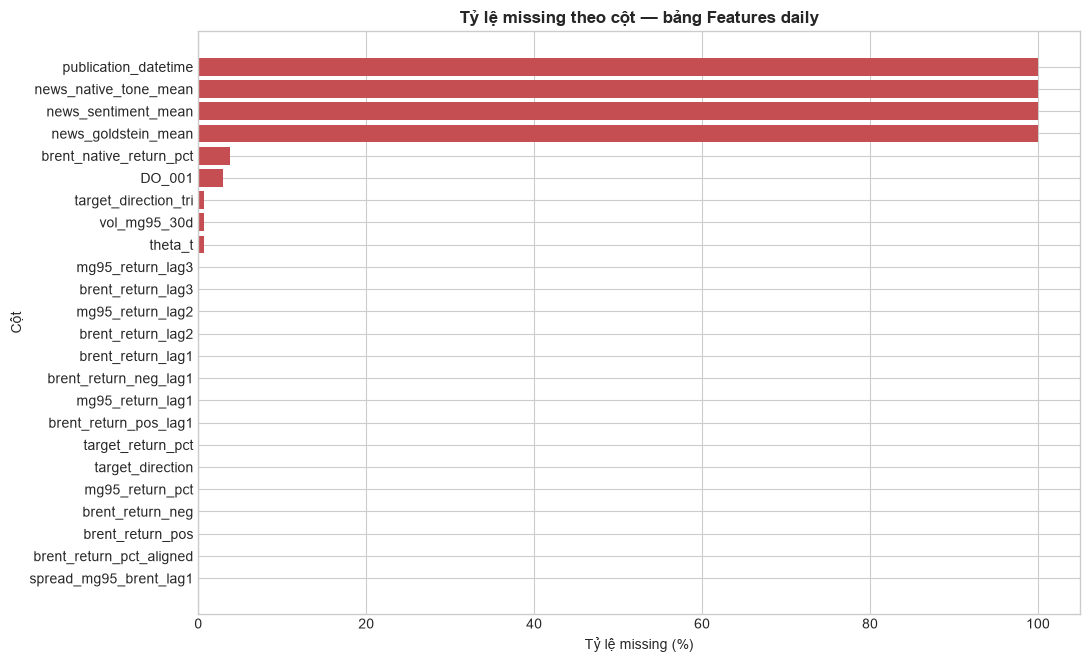

In [4]:
quality = pd.DataFrame({
    "Missing (n)": df.isna().sum(),
    "Missing (%)": (df.isna().mean() * 100).round(2),
})
quality = quality.loc[quality["Missing (n)"].gt(0)].sort_values("Missing (%)", ascending=False)
print(f"Số hàng trùng hoàn toàn: {int(df.duplicated().sum()):,}")
print(f"Số ngày market_date trùng: {int(df['market_date'].duplicated().sum()):,}")
print(f"Số giá không dương trong các chuỗi giá: {int((df[[c for c in ['MG95','MG92','DO_001','DO_005','brent_close'] if c in df]].le(0)).sum().sum()):,}")
if quality.empty:
    print("Không có giá trị missing trong bảng chính.")
else:
    display(quality)
    fig, ax = plt.subplots(figsize=(11, max(3, 0.28 * len(quality))))
    ax.barh(quality.index[::-1], quality["Missing (%)"][::-1], color="#c44e52")
    ax.set(title="Tỷ lệ missing theo cột — bảng Features daily", xlabel="Tỷ lệ missing (%)", ylabel="Cột")
    fig.tight_layout()
    plt.show()

## 3. Phân phối các mức giá chính

Thống kê mô tả và histogram cho biết đơn vị/thang đo, độ lệch và miền giá của các chuỗi hàng hóa. Giá có xu hướng theo thời gian nên không dùng tương quan giữa **mức giá** để kết luận hai thị trường liên hệ chặt chẽ; phần tương quan sẽ xét lợi suất.

,count,mean,std,min,1%,25%,50%,75%,99%,max
MG95,4428.0,88.288,25.567,16.12,35.906,70.438,84.240,109.490,145.317,160.86
MG92,4428.0,85.483,25.244,14.64,33.265,67.632,81.615,106.622,141.622,155.72
DO_001,4300.0,91.613,28.137,22.92,37.140,71.508,87.435,117.845,154.896,186.03
DO_005,4428.0,91.608,29.013,20.75,35.994,70.978,87.095,118.072,168.945,182.60
brent_close,4428.0,77.694,24.125,19.33,31.057,60.395,74.760,98.163,127.043,146.08


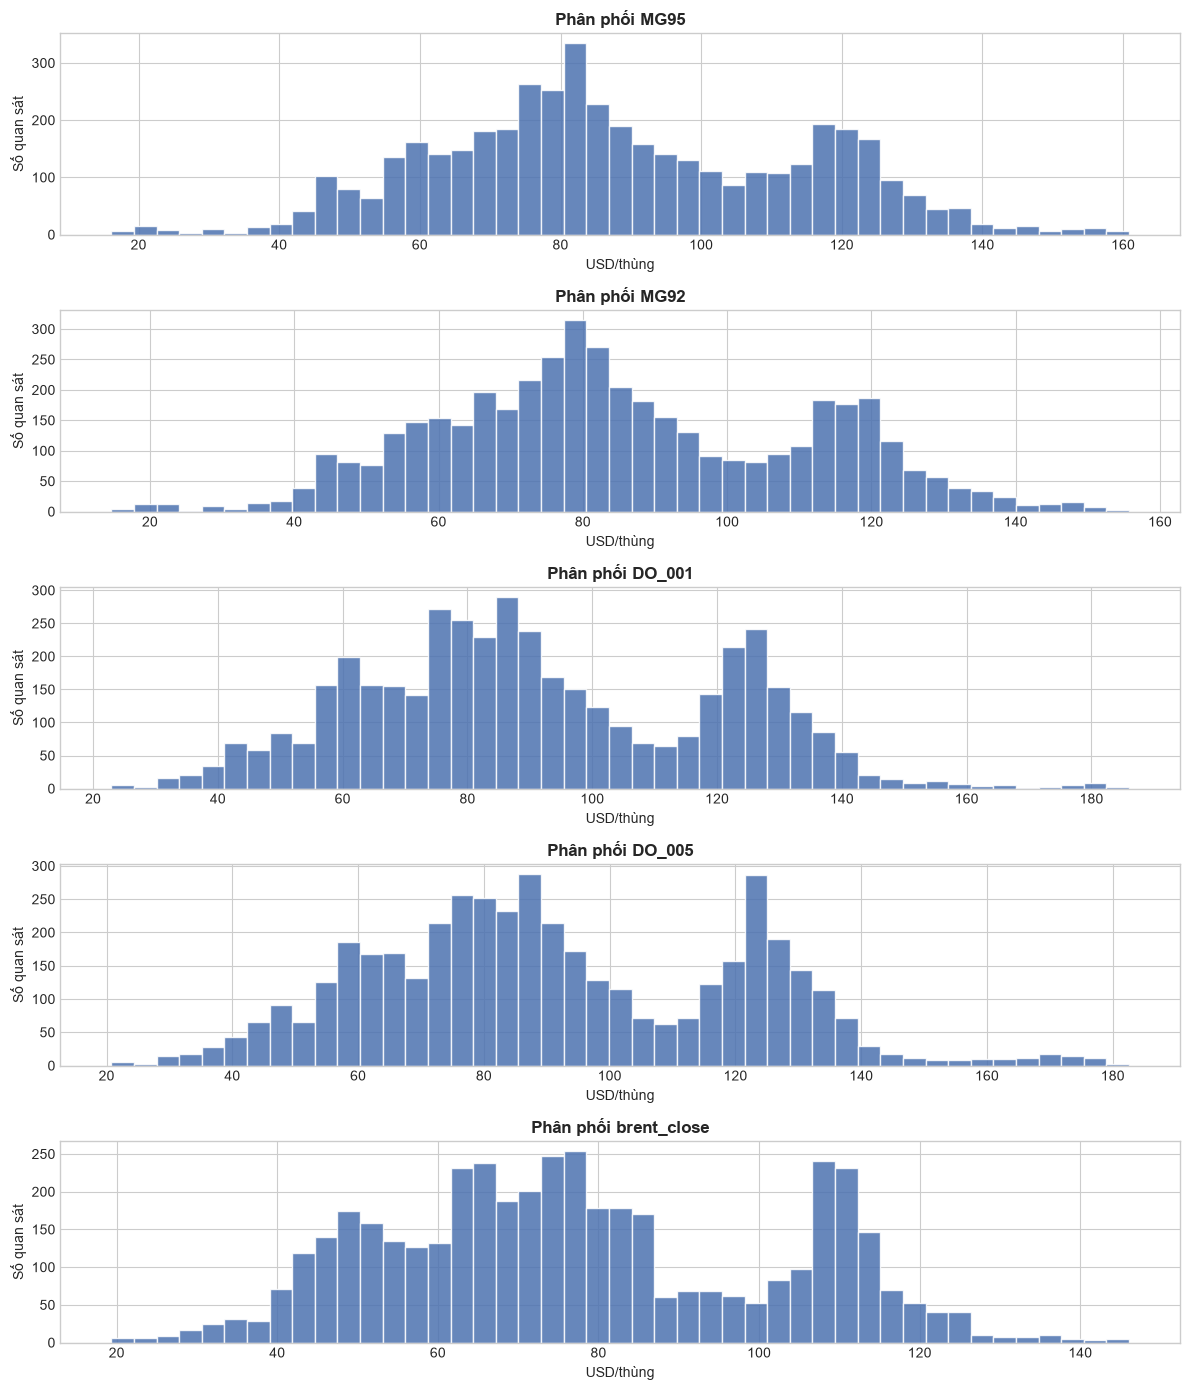

In [5]:
price_cols = [c for c in ["MG95", "MG92", "DO_001", "DO_005", "brent_close"] if c in df]
display(df[price_cols].describe(percentiles=[.01, .25, .5, .75, .99]).T.round(3))

fig, axes = plt.subplots(len(price_cols), 1, figsize=(12, 2.8 * len(price_cols)))
if len(price_cols) == 1:
    axes = [axes]
for ax, column in zip(axes, price_cols):
    values = df[column].dropna()
    ax.hist(values, bins=45, color="#4c72b0", alpha=0.85, edgecolor="white")
    ax.set(title=f"Phân phối {column}", xlabel="USD/thùng", ylabel="Số quan sát")
fig.tight_layout()
plt.show()

## 4. Xu hướng giá theo thời gian

Các chuỗi giá được vẽ cùng đơn vị để nhìn chu kỳ và các giai đoạn khác biệt. Mức giá Platts và Brent không phải cùng một tài sản/điều kiện giao hàng; khoảng cách giữa chúng không mặc nhiên là lợi nhuận lọc dầu.

> **Ghi chú thuyết trình:** chỉ mô tả những gì quan sát được trong biểu đồ, chưa gán nguyên nhân cho biến động.

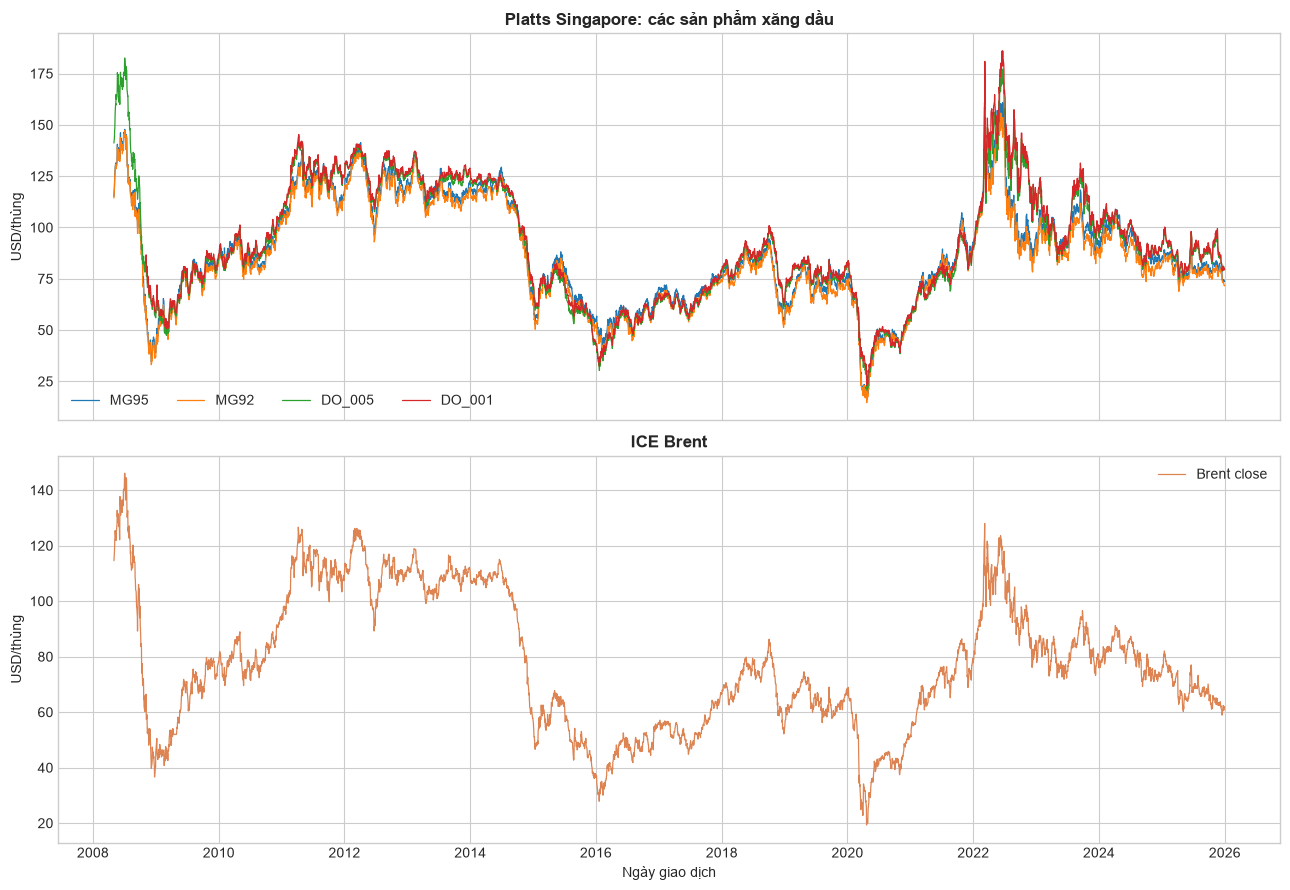

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True)
platts_cols = [c for c in ["MG95", "MG92", "DO_005", "DO_001"] if c in df]
for column in platts_cols:
    axes[0].plot(df["market_date"], df[column], linewidth=0.9, label=column)
axes[0].set(title="Platts Singapore: các sản phẩm xăng dầu", ylabel="USD/thùng")
axes[0].legend(ncol=4)
if "brent_close" in df:
    axes[1].plot(df["market_date"], df["brent_close"], color="#dd8452", linewidth=0.9, label="Brent close")
    axes[1].set(title="ICE Brent", xlabel="Ngày giao dịch", ylabel="USD/thùng")
    axes[1].legend()
fig.tight_layout()
plt.show()

## 5. Lợi suất: phân phối, biến động và giá trị cực đoan

Pipeline lưu lợi suất MG95 dưới dạng **log-return nhân 100**. Với Brent, notebook ghép `brent_return_pct` từ `brent_continuous.parquet` theo **ngày giao dịch Brent thực tế**; ngày ICE nghỉ được giữ là missing, không bị biến thành lợi suất 0 do giá carry-forward. Các biến là log-return × 100, không phải phần trăm thay đổi chính xác.

IQR bên dưới chỉ đánh dấu quan sát xa; không loại điểm nào. Cú sốc có thể là sự kiện thị trường thật và cần kiểm tra nguồn trước khi xử lý.

,count,mean,std,min,1%,5%,50%,95%,99%,max,skew,excess_kurtosis
mg95_return_pct,4427.0,-0.010,2.477,-26.858,-6.852,-3.530,0.065,3.346,6.234,27.865,-0.775,16.772
brent_native_return_pct,4262.0,-0.008,2.384,-27.976,-6.991,-3.775,0.064,3.321,6.143,19.077,-0.762,13.076


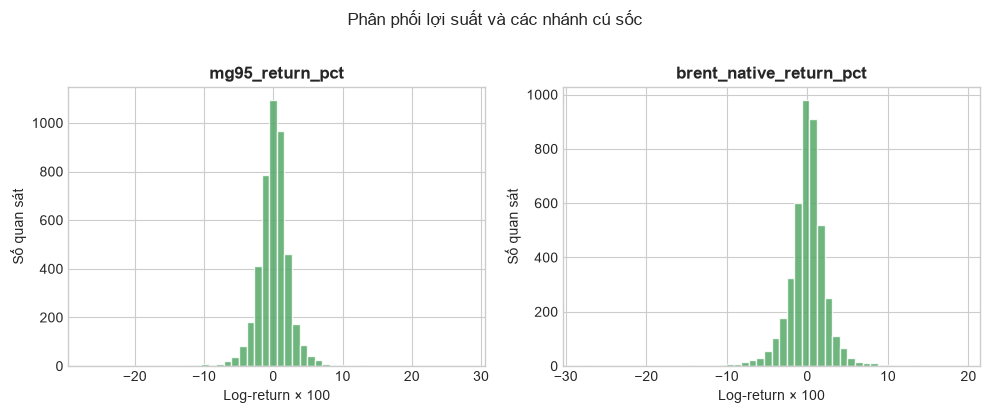

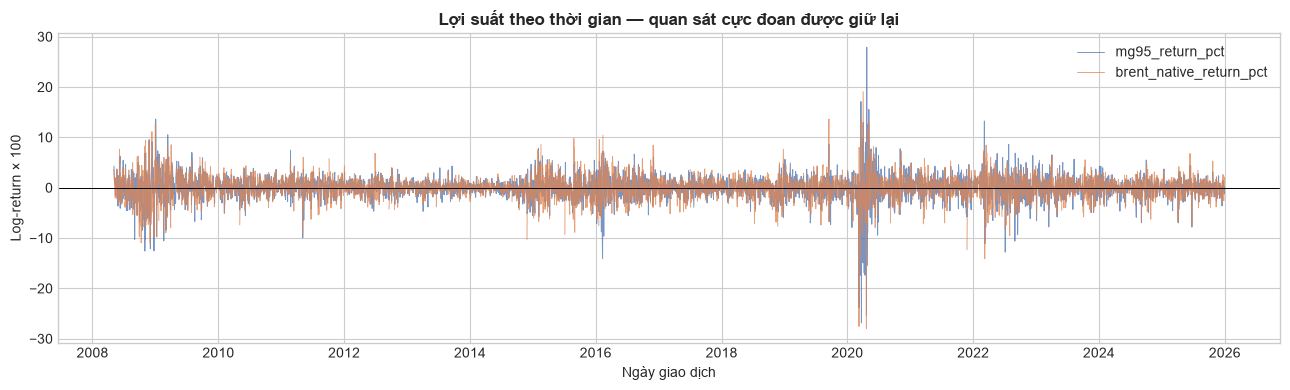

In [7]:
return_cols = [c for c in ["mg95_return_pct", "brent_native_return_pct"] if c in df]
return_stats = df[return_cols].describe(percentiles=[.01, .05, .5, .95, .99]).T
return_stats["skew"] = df[return_cols].skew()
return_stats["excess_kurtosis"] = df[return_cols].kurtosis()
display(return_stats.round(3))

fig, axes = plt.subplots(1, len(return_cols), figsize=(5 * len(return_cols), 4))
if len(return_cols) == 1:
    axes = [axes]
for ax, column in zip(axes, return_cols):
    values = df[column].dropna()
    ax.hist(values, bins=50, color="#55a868", alpha=0.85, edgecolor="white")
    ax.set(title=column, xlabel="Log-return × 100", ylabel="Số quan sát")
fig.suptitle("Phân phối lợi suất và các nhánh cú sốc", y=1.02)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(13, 4))
for column, color in [("mg95_return_pct", "#4c72b0"), ("brent_native_return_pct", "#dd8452")]:
    if column in df:
        ax.plot(df["market_date"], df[column], linewidth=0.7, alpha=0.75, label=column, color=color)
ax.axhline(0, color="black", linewidth=0.7)
ax.set(title="Lợi suất theo thời gian — quan sát cực đoan được giữ lại", xlabel="Ngày giao dịch", ylabel="Log-return × 100")
ax.legend()
fig.tight_layout()
plt.show()

In [8]:
outlier_rows = []
for column in ["mg95_return_pct", "brent_native_return_pct"]:
    if column not in df:
        continue
    values = df[column].dropna()
    q1, q3 = values.quantile([.25, .75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_rows.append({
        "Biến": column,
        "Ngưỡng IQR thấp": low,
        "Ngưỡng IQR cao": high,
        "Số điểm ngoài IQR": int(((values < low) | (values > high)).sum()),
        "Giá trị nhỏ nhất": values.min(),
        "Giá trị lớn nhất": values.max(),
    })
display(pd.DataFrame(outlier_rows).set_index("Biến").round(3))
flag_cols = [c for c in ["mg95_outlier_flag", "brent_outlier_flag_aligned", "economic_shock_flag"] if c in df]
if flag_cols:
    display(df[flag_cols].sum().rename("Số cờ bật").to_frame())
print("Ngưỡng IQR là công cụ sàng lọc mô tả; không đồng nghĩa quan sát sai và không được dùng làm lý do tự động xóa dữ liệu.")

,Ngưỡng IQR thấp,Ngưỡng IQR cao,Số điểm ngoài IQR,Giá trị nhỏ nhất,Giá trị lớn nhất
Biến,,,,,
mg95_return_pct,-4.730,4.780,201,-26.858,27.865
brent_native_return_pct,-4.296,4.392,254,-27.976,19.077


,Số cờ bật
mg95_outlier_flag,4
brent_outlier_flag_aligned,2
economic_shock_flag,4


Ngưỡng IQR là công cụ sàng lọc mô tả; không đồng nghĩa quan sát sai và không được dùng làm lý do tự động xóa dữ liệu.


## 6. Thay đổi theo năm và mùa vụ theo tháng

Bảng năm cho thấy mức giá trung bình, biên độ và độ biến động của lợi suất. Bảng tháng tóm tắt lợi suất trung bình và độ biến động theo tháng dương lịch. Đây là mô tả lịch sử trên mẫu hiện có; chưa phải bằng chứng mùa vụ có ý nghĩa thống kê.

,Số phiên,MG95 — giá TB,MG92 — giá TB,DO_005 — giá TB,brent_close — giá TB,mg95_return_pct — vol năm hóa,brent_native_return_pct — vol năm hóa
Năm,,,,,,,
2008,168,100.72,99.16,123.37,98.59,60.03,63.63
2009,252,70.38,68.18,70.42,62.91,46.10,45.34
2010,251,88.41,86.23,90.35,80.33,25.94,27.11
2011,249,119.80,117.43,126.28,110.98,28.85,31.01
2012,251,123.42,120.26,128.10,111.70,21.79,23.88
2013,251,119.00,116.03,123.27,108.75,18.69,16.72
2014,251,110.97,108.16,112.69,99.55,21.94,20.92
2015,248,69.17,66.08,64.47,53.46,37.15,44.72
2016,252,56.26,53.43,52.24,45.21,43.26,44.50


,Số phiên,MG95 log-return TB,MG95 vol năm hóa,Brent log-return TB,Brent vol năm hóa
Tháng,,,,,
1,349,0.21,35.81,0.12,33.36
2,326,0.13,38.94,0.23,35.64
3,371,-0.15,55.47,-0.17,51.00
4,351,0.12,58.13,0.17,48.96
5,366,0.11,38.97,0.09,35.40
6,378,0.07,35.00,0.11,33.80
7,393,-0.07,31.79,-0.05,31.26
8,376,-0.03,30.68,-0.07,32.46
9,380,-0.10,35.05,-0.10,35.87


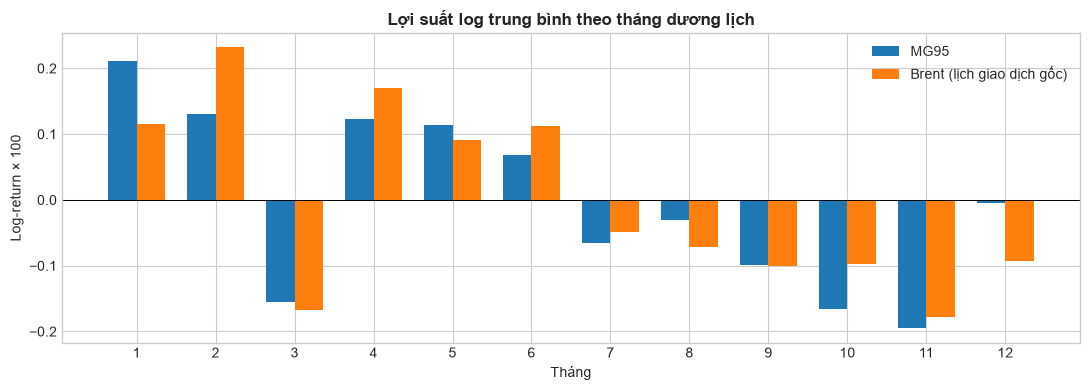

In [9]:
work = df.copy()
work["year"] = work["market_date"].dt.year
work["month"] = work["market_date"].dt.month
annual_rows = []
for year, group in work.groupby("year"):
    row = {"Năm": year, "Số phiên": len(group)}
    for price in ["MG95", "MG92", "DO_005", "brent_close"]:
        if price in group:
            row[f"{price} — giá TB"] = group[price].mean()
    for ret in ["mg95_return_pct", "brent_native_return_pct"]:
        if ret in group:
            row[f"{ret} — vol năm hóa"] = group[ret].std() * np.sqrt(252)
    annual_rows.append(row)
annual = pd.DataFrame(annual_rows).set_index("Năm")
display(annual.round(2))

monthly_rows = []
for month, group in work.groupby("month"):
    monthly_rows.append({
        "Tháng": month,
        "Số phiên": len(group),
        "MG95 log-return TB": group["mg95_return_pct"].mean(),
        "MG95 vol năm hóa": group["mg95_return_pct"].std() * np.sqrt(252),
        "Brent log-return TB": group["brent_native_return_pct"].mean(),
        "Brent vol năm hóa": group["brent_native_return_pct"].std() * np.sqrt(252),
    })
monthly = pd.DataFrame(monthly_rows).set_index("Tháng")
display(monthly.round(2))
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(monthly.index - 0.18, monthly["MG95 log-return TB"], width=0.36, label="MG95")
ax.bar(monthly.index + 0.18, monthly["Brent log-return TB"], width=0.36, label="Brent (lịch giao dịch gốc)")
ax.axhline(0, color="black", linewidth=0.7)
ax.set(title="Lợi suất log trung bình theo tháng dương lịch", xlabel="Tháng", ylabel="Log-return × 100")
ax.set_xticks(range(1, 13))
ax.legend()
fig.tight_layout()
plt.show()

## 7. Đặc trưng sản phẩm và quan hệ Platts–Brent

Chênh lệch sản phẩm giúp mô tả cấu trúc giá, nhưng `MG95 - Brent` ở cùng dòng trong bảng đã ghép là **chênh lệch giá tham khảo**, không phải crack spread ròng hoặc biên lợi nhuận của nhà máy. Giá Brent trong panel ghép có thể được carry-forward vào ngày khác lịch; notebook dùng lợi suất nguồn trên lịch giao dịch Brent để tránh coi ngày nghỉ là lợi suất 0.

Tương quan bên dưới dùng log-return, không dùng mức giá. Lợi suất Brent được lấy theo lịch giao dịch Brent thực tế; các ngày Brent nghỉ không được coi là lợi suất 0. Hệ số đồng thời và trễ là thống kê mô tả, không xác định quan hệ nhân quả.

,count,mean,std,min,5%,50%,95%,max
spread_mg95_mg92,4428.0,2.81,1.21,0.26,1.28,2.61,5.24,9.65
spread_mg95_do005,4428.0,-3.32,8.01,-46.47,-19.04,-2.26,6.23,18.57
spread_mg95_brent,4428.0,10.59,5.81,-14.62,2.05,10.56,19.13,46.21


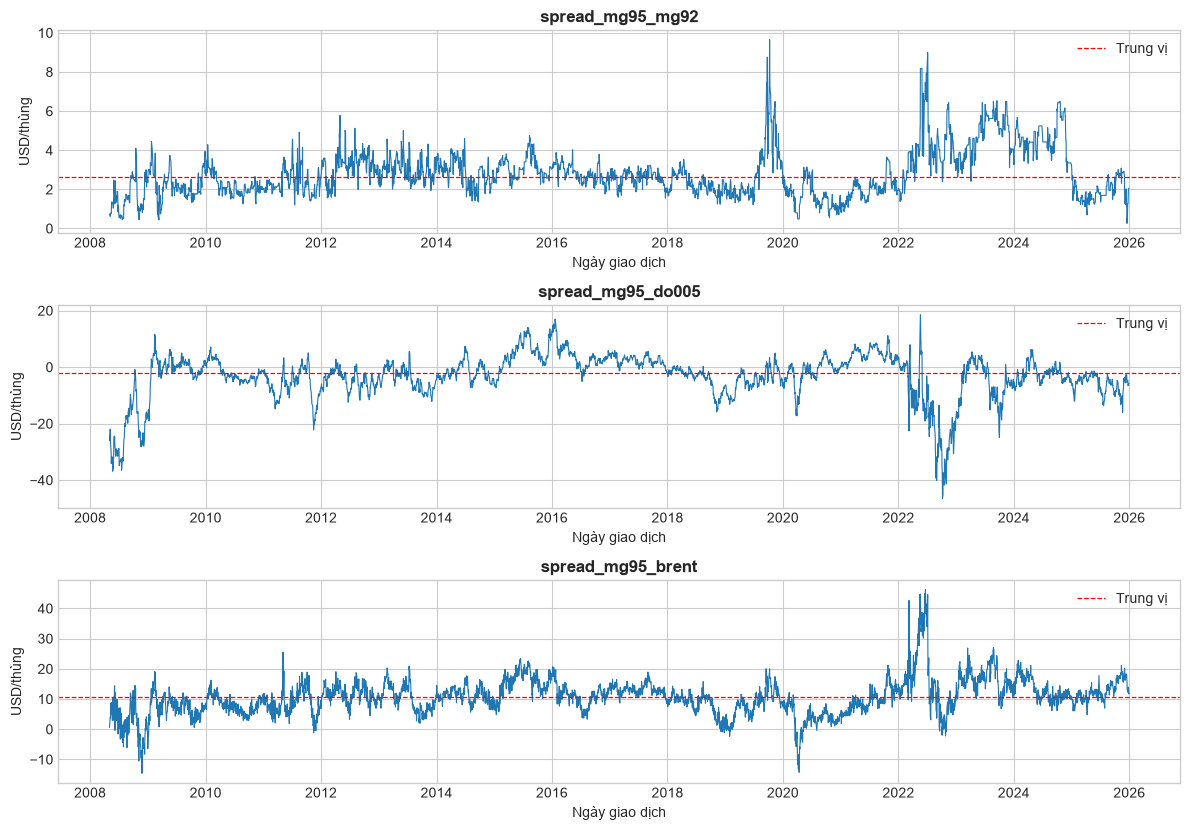

,MG95,Brent (ngày giao dịch Brent),MG92,DO_005,DO_001
MG95,1.00,0.24,0.99,0.79,0.78
Brent (ngày giao dịch Brent),0.24,1.00,0.24,0.25,0.26
MG92,0.99,0.24,1.00,0.80,0.80
DO_005,0.79,0.25,0.80,1.00,1.00
DO_001,0.78,0.26,0.80,1.00,1.00


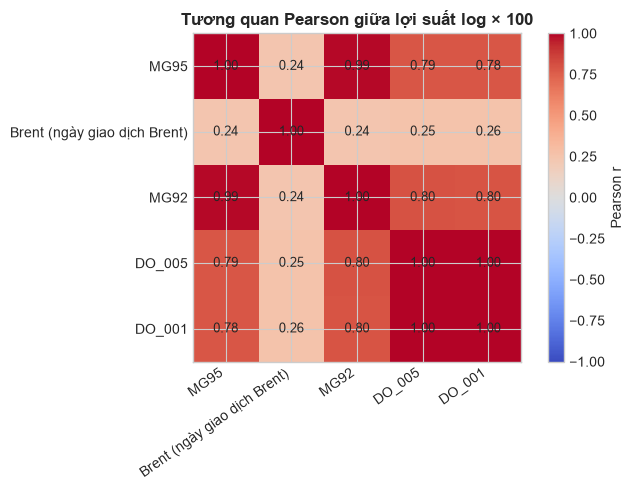

Tương quan cùng ngày trên các ngày có cả hai thị trường: 0.238
Tương quan với lợi suất Brent ở ngày giao dịch chung trước đó: 0.566
Lợi suất hai thị trường được tính trên lịch giao dịch riêng; ngày nghỉ Brent là missing. Đây là mô tả, không chứng minh nhân quả hay năng lực dự báo.


In [10]:
for column, left, right in [
    ("spread_mg95_mg92", "MG95", "MG92"),
    ("spread_mg95_do005", "MG95", "DO_005"),
    ("spread_mg95_brent", "MG95", "brent_close"),
]:
    if column not in df and left in df and right in df:
        df[column] = df[left] - df[right]
spread_cols = [c for c in ["spread_mg95_mg92", "spread_mg95_do005", "spread_mg95_brent"] if c in df]
display(df[spread_cols].describe(percentiles=[.05, .5, .95]).T.round(2))

fig, axes = plt.subplots(len(spread_cols), 1, figsize=(12, 2.8 * max(1, len(spread_cols))))
if len(spread_cols) == 1:
    axes = [axes]
for ax, column in zip(axes, spread_cols):
    ax.plot(df["market_date"], df[column], linewidth=0.8)
    ax.axhline(df[column].median(), color="red", linestyle="--", linewidth=0.9, label="Trung vị")
    ax.set(title=column, xlabel="Ngày giao dịch", ylabel="USD/thùng")
    ax.legend()
fig.tight_layout()
plt.show()

ret_map = {
    "MG95": "mg95_return_pct",
    "Brent (ngày giao dịch Brent)": "brent_native_return_pct",
    "MG92": None,
    "DO_005": None,
    "DO_001": None,
}
returns = pd.DataFrame(index=df.index)
for label, column in ret_map.items():
    if column and column in df:
        returns[label] = df[column]
    elif label in df:
        returns[label] = np.log(df[label] / df[label].shift(1)) * 100
corr = returns.corr(min_periods=30)
display(corr.round(2))
fig, ax = plt.subplots(figsize=(7, 5))
image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=35, ha="right")
ax.set_yticks(range(len(corr.index)), corr.index)
for i in range(len(corr.index)):
    for j in range(len(corr.columns)):
        value = corr.iloc[i, j]
        if pd.notna(value):
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=9)
ax.set_title("Tương quan Pearson giữa lợi suất log × 100")
fig.colorbar(image, ax=ax, label="Pearson r")
fig.tight_layout()
plt.show()

if "brent_calendar_exact_match" in df:
    paired_market_returns = df[["market_date", "mg95_return_pct", "brent_native_return_pct"]].dropna()
    same_session_corr = paired_market_returns["mg95_return_pct"].corr(paired_market_returns["brent_native_return_pct"])
    previous_common_corr = paired_market_returns["mg95_return_pct"].corr(
        paired_market_returns["brent_native_return_pct"].shift(1)
    )
    print(f"Tương quan cùng ngày trên các ngày có cả hai thị trường: {same_session_corr:.3f}")
    print(f"Tương quan với lợi suất Brent ở ngày giao dịch chung trước đó: {previous_common_corr:.3f}")
    print("Lợi suất hai thị trường được tính trên lịch giao dịch riêng; ngày nghỉ Brent là missing. Đây là mô tả, không chứng minh nhân quả hay năng lực dự báo.")

## 8. Biến mục tiêu và tình trạng dữ liệu tin tức

`target_return_pct` và các `target_direction*` là kết quả cần dự báo ở phiên kế tiếp. Chúng được mô tả riêng để nhóm hiểu phân bố nhãn; không đưa target vào ma trận tương quan predictor.

Bảng RQ2 có trường tin tức, nhưng cần kiểm tra thực tế dataset: `news_count = 0` và sentiment missing toàn bộ có nghĩa là hiện chưa có biến thiên tin tức để phân tích/đánh giá đóng góp mô hình tin tức.

In [11]:
target_summary = {}
for column in ["target_return_pct", "target_direction", "target_direction_tri"]:
    if column in df:
        target_summary[column] = {
            "Số missing": int(df[column].isna().sum()),
            "Số giá trị hợp lệ": int(df[column].notna().sum()),
            "Số nhãn khác nhau": int(df[column].nunique(dropna=True)),
        }
display(pd.DataFrame(target_summary).T)
for column in ["target_direction", "target_direction_tri"]:
    if column in df:
        display(df[column].value_counts(dropna=False).sort_index().rename("Số phiên").to_frame().rename_axis(column))

news_cols = [c for c in ["news_count", "news_sentiment_mean", "news_native_tone_mean",
                          "news_goldstein_mean", "news_dataset_present"] if c in df]
if news_cols:
    news_report = pd.DataFrame({
        "Kiểu": df[news_cols].dtypes.astype(str),
        "Missing": df[news_cols].isna().sum(),
        "Giá trị khác nhau": df[news_cols].nunique(dropna=True),
        "Giá trị mẫu": [df[c].dropna().unique()[:5].tolist() for c in news_cols],
    }, index=news_cols)
    display(news_report)
    if "news_dataset_present" in df:
        print("news_dataset_present:", df["news_dataset_present"].value_counts(dropna=False).to_dict())
    if "news_count" in df:
        print("news_count == 0:", int(df["news_count"].eq(0).sum()), "/", len(df))

,Số missing,Số giá trị hợp lệ,Số nhãn khác nhau
target_return_pct,1,4427,4411
target_direction,1,4427,2
target_direction_tri,31,4397,3


,Số phiên
target_direction,
0.0,2153
1.0,2274
NaN,1


,Số phiên
target_direction_tri,
-1,1315
0,1716
1,1366
<NA>,31


,Kiểu,Missing,Giá trị khác nhau,Giá trị mẫu
news_count,int64,0,1,[0]
news_sentiment_mean,float64,4428,0,[]
news_native_tone_mean,float64,4428,0,[]
news_goldstein_mean,float64,4428,0,[]
news_dataset_present,bool,0,1,[False]


news_dataset_present: {False: 4428}
news_count == 0: 4428 / 4428


## 9. Nhận xét EDA và việc cần làm tiếp

Dùng các bảng/biểu đồ đã tính ở trên để tự ghi nhận điều nhóm quan sát được. Không nên kết luận nhân quả từ tương quan, không gọi chênh lệch giá đơn giản là lợi nhuận lọc dầu, và không loại điểm cực đoan trước khi truy nguyên.

### Checklist trước khi chuyển sang mô hình
- Xác minh missing của từng biến theo nguồn và quyết định xử lý có ghi nhận; đặc biệt DO_001, các target ở rìa mẫu và warm-up của rolling features.
- Xác minh timestamp/availability PIT: pipeline đánh dấu timestamp availability là proxy, nên kết quả audit không thay thế timestamp nguồn đã xác thực.
- Nếu dùng Stream 2 để đánh giá M6/tin tức, cần ingest và kiểm tra dữ liệu tin trước; hiện tại các trường sentiment không có quan sát.
- Giữ target tách khỏi predictor; chia train/test theo thời gian, không xáo trộn ngẫu nhiên.
- Ghi phiên bản file, ngày chạy và phạm vi mẫu khi đưa bảng/biểu đồ vào báo cáo.